# PLOTS

## Libraries

In [1]:
import json
import os
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.spatial.distance import pdist
import matplotlib.colors as mcolors

## Methods

In [2]:
def darken(color, factor=0.65):
    rgb = np.array(mcolors.to_rgb(color))
    return tuple(factor * rgb)


def arr(name, arrays, default=None):
    return arrays[name] if name in arrays.files else default


def fmt_est_se(est, se, digits=3):
    if pd.isna(est):
        return ""
    if pd.isna(se):
        return f"{est:.{digits}f}"
    return f"{est:.{digits}f} ({se:.{digits}f})"


def model_keys_for_spec(spec, spec_dict, our_name):
    keys = []
    for display_name in spec_dict["models"]:
        key = "PAC" if display_name == our_name else display_name
        if key == "ERGM" and spec == 3:
            continue
        keys.append(key)
    return keys


def selected_stat_indices(stats, spec_dict):
    if stats is None:
        requested = labels
    elif stats == "paper":
        requested = spec_dict["paper_stats"]
    else:
        requested = list(stats)
    return [labels.index(x) for x in requested if x in labels]


def statistic_models(spec, our_name):
    models = []
    if ergm_stats is not None and spec != 3:
        models.append(("ERGM", np.asarray(ergm_stats, float)))
    if pac_stats is not None:
        models.append((our_name, np.asarray(pac_stats, float)))
    if lolog_stats is not None and spec in (2, 3):
        models.append(("LOLOG", np.asarray(lolog_stats, float)))
    return models

# ---------------------------------------------------------------------
# Degree-distribution GoF helpers
# ---------------------------------------------------------------------
def degree_hist_matrix(nets, kind, max_degree=15):
    nets = np.asarray(nets)
    if nets.ndim != 3:
        raise ValueError("Expected networks with shape (n_sim, n_nodes, n_nodes)")
    axis = 1 if kind == "indeg" else 2
    # For adjacency A[i,j] = i -> j: indegree = column sums, outdegree = row sums.
    if kind == "indeg":
        degrees = nets.sum(axis=1)
    elif kind == "outdeg":
        degrees = nets.sum(axis=2)
    else:
        raise ValueError("kind must be 'indeg' or 'outdeg'")
    out = np.zeros((nets.shape[0], max_degree + 1), dtype=float)
    for i, d in enumerate(degrees):
        out[i] = np.bincount(np.minimum(d.astype(int), max_degree), minlength=max_degree + 1)[:max_degree + 1]
    return out


def observed_degree_hist(A, kind, max_degree=15):
    if kind == "indeg":
        d = A.sum(axis=0)
    elif kind == "outdeg":
        d = A.sum(axis=1)
    else:
        raise ValueError("kind must be 'indeg' or 'outdeg'")
    return np.bincount(np.minimum(d.astype(int), max_degree), minlength=max_degree + 1)[:max_degree + 1]


def degree_models(kind, spec, maxd, our_name):
    models = []
    if kind == "indeg":
        ergm_pre = ergm_indeg
    else:
        ergm_pre = ergm_outdeg

    if ergm_pre is not None and spec != 3:
        models.append(("ERGM", np.asarray(ergm_pre, float)))
    if pac_nets is not None:
        models.append((our_name, degree_hist_matrix(pac_nets, kind, maxd)))
    if lolog_nets is not None and spec in (2, 3):
        models.append(("LOLOG", degree_hist_matrix(lolog_nets, kind, maxd)))
    return models


def capped_hist(values, maxd):
    """
    Count values in classes 0, ..., maxd-1, maxd+.
    """
    values = np.asarray(values, dtype=int)
    return np.bincount(
        np.minimum(values, maxd),
        minlength=maxd + 1
    )[:maxd + 1]


def degree_hists(nets, maxd):
    """
    In-degree and out-degree count vectors for each simulated network.

    Returns
    -------
    H_in  : shape (n_networks, maxd + 1)
    H_out : shape (n_networks, maxd + 1)
    """
    nets = np.asarray(nets)

    H_in = np.array([
        capped_hist(A.sum(axis=0), maxd)
        for A in nets
    ])

    H_out = np.array([
        capped_hist(A.sum(axis=1), maxd)
        for A in nets
    ])

    return H_in, H_out


def shared_partner_hist(A, maxd):
    """
    Edgewise transitive shared-partner (OTP) count vector.

    For every edge i -> j, (A @ A)[i, j] counts the number of
    two-paths i -> k -> j. The histogram records how many edges
    have 0, 1, ..., maxd-1, maxd+ shared partners.
    """
    A = np.asarray(A)
    S = A @ A
    esp = S[A == 1]

    return capped_hist(esp, maxd)


def shared_partner_hists(nets, maxd):
    """
    Edgewise shared-partner count vector for each simulated network.
    """
    return np.array([
        shared_partner_hist(A, maxd)
        for A in np.asarray(nets)
    ])


# ----------------------------------------------------------------------------
# Metrics
# ----------------------------------------------------------------------------

def energy_score_counts(H, obs):
    """
    Energy Score for a distribution represented by count vectors.

    H   : simulated count vectors, shape (M, K)
    obs : observed count vector, shape (K,)

    ES = mean_i ||H_i - obs||
         - 1/2 mean_{i<j} ||H_i - H_j||
    """
    H = np.asarray(H, dtype=float)
    obs = np.asarray(obs, dtype=float)

    if len(H) < 2:
        return np.nan

    deviation = np.linalg.norm(H - obs, axis=1).mean()
    dispersion = 0.5 * pdist(H, metric="euclidean").mean()

    return float(deviation - dispersion)


def mean_l1(H, obs):
    """
    Mean L1 distance between simulated and observed histograms.
    """
    H = np.asarray(H, dtype=float)
    obs = np.asarray(obs, dtype=float)

    return float(
        np.abs(H - obs).sum(axis=1).mean()
    )

## Specs

In [3]:
# OUR ALGORITHM NAME
OUR_NAME = "BaCon"

In [4]:
# ---------------------------------------------------------------------
# Specifications 
# ---------------------------------------------------------------------
SPECIFICATIONS = {
    1: {
        "pac_patterns": [
            "run_*_PAC_ukFaculty_GWESP_final",
            "run_*_PAC_ukFaculty_GWESP",
        ],
        "edge_candidates": ["data/ukfaculty_edges.csv"],
        "paper_stats": ["nodefactor.GroupC.1", "gwesp"],
        "models": ["ERGM", OUR_NAME],
        "outdir": "ukFaculty_spec1",
    },
    2: {
        "pac_patterns": [
            "run_*_PAC_office_uni2005_final",
            "run_*_PAC_office_uni2005",
        ],
        "edge_candidates": ["data/office_sailer/office_uni2005_edges.csv"],
        "paper_stats": ["edges", "edgecov.use"],
        "models": ["ERGM", OUR_NAME, "LOLOG"],
        "outdir": "office_uni2005_spec2"
    },
    3: {
        "pac_patterns": [
            "run_*_PAC_office_uni2005_gwdeg_final",
            "run_*_PAC_office_uni2005_gwdeg",
        ],
        "edge_candidates": ["data/office_sailer/office_uni2005_edges.csv"],
        "paper_stats": ["edges", "edgecov.use"],
        "models": [OUR_NAME, "LOLOG"],
        "outdir": "office_uni2005_spec3"
    },
}

In [5]:
# ---------------------------------------------------------------------
# Pretty names for the statistics
# ---------------------------------------------------------------------
PRETTY = {
    "edges": r"$|E|$",
    "mutual": r"$\operatorname{rec}$",
    "gwesp": r"$T_{\gamma}$",
    "gwodeg": r"$D^{\mathrm{out}}_{\phi}$",
    "gwideg": r"$D^{\mathrm{in}}_{\phi}$",
    "nodematch.GroupC": r"$H_{\mathrm{GroupC}}$",
    "nodefactor.GroupC.1": r"$F^{\mathrm{GroupC}}_1$",
    "nodefactor.GroupC.2": r"$F^{\mathrm{GroupC}}_2$",
    "edgecov.use": r"$C_{\mathrm{use}}$",
    "edgecov.team": r"$C_{\mathrm{team}}$",
    "edgecov.floor": r"$C_{\mathrm{floor}}$",
    "edgecov.metric": r"$C_{\mathrm{metric}}$",
}

In [8]:
# ---------------------------------------------------------------------
# USER SETTINGS
# ---------------------------------------------------------------------
SPECIFICATION = 3              # 1, 2, or 3
STATISTICS_TO_PLOT = None     # "paper", None (= all), or a list of saved statistic labels
MAX_DEGREE = 15                   # last class is MAX_DEGREE+
SHOW_LOLOG_COEFFICIENTS = True   # LOLOG terms are not directly comparable in Specs. 2/3

# Consistent plotting labels/colors.
MODEL_COLORS = {
    "ERGM": "#B64949",
    OUR_NAME: "#3568A8",
    "LOLOG": "#4E8B57",
}

DISPLAY_NAME = {"PAC": OUR_NAME, "ERGM": "ERGM", "LOLOG": "LOLOG"}

SPEC = SPECIFICATIONS[SPECIFICATION]
PROJECT_ROOT = "/Users/giulia/Documents/Projects/Research/ExtraCanNullModels/PACE"

PAC_RUN = os.path.join(PROJECT_ROOT, "output", SPEC["outdir"])
EDGE_FILE = os.path.join(PROJECT_ROOT, SPEC["edge_candidates"][0])
SCALABILITY_DIR = os.path.join(PROJECT_ROOT, "output", "scalability")
SENSITIVITY_DIR = os.path.join(PROJECT_ROOT, "output", 
                               "epsilon_sensitivity", 
                               f"spec_3")
ROBUST_DIR = os.path.join(PROJECT_ROOT, "output", "robustness")

PLOT_DIR = os.path.join(PROJECT_ROOT, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

## Data Loading

In [7]:
# ---------------------------------------------------------------------
# Load saved arrays, tables, metrics, and observed network
# ---------------------------------------------------------------------
arrays = np.load(os.path.join(PAC_RUN, "arrays.npz"), allow_pickle=False)

labels = [str(x) for x in arr("labels", arrays)]
g_obs = np.asarray(arr("g_obs", arrays), dtype=float)
pac_stats = arr("gof_samples", arrays)
pac_nets = arr("gof_networks", arrays)
ergm_stats = arr("ergm_simstats", arrays)
ergm_indeg = arr("ergm_indeg_sim", arrays)
ergm_outdeg = arr("ergm_outdeg_sim", arrays)
lolog_stats = arr("lolog_stats", arrays)
lolog_nets = arr("lolog_networks", arrays)

with open(os.path.join(PAC_RUN, "results_summary.json"), "r") as f:
    summary = json.load(f)
with open(os.path.join(PAC_RUN, "thesis_metrics.json"), "r") as f:
    metrics = json.load(f)

lolog_own_metrics = None
if SPECIFICATION in (2, 3):
    lolog_metrics_file = os.path.join(PAC_RUN, "lolog_own_metrics.json")
    with open(lolog_metrics_file, "r", encoding="utf-8") as f:
        lolog_own_metrics = json.load(f)

coefficients = pd.read_csv(os.path.join(PAC_RUN, "coefficients.csv"))
try:
    lolog_coefficients = pd.read_csv(os.path.join(PAC_RUN, "lolog_coefficients.csv"))
except FileNotFoundError:
    lolog_coefficients = None

A_obs = None
ed = pd.read_csv(EDGE_FILE)
n_from_saved = None
for nets in (pac_nets, lolog_nets):
    if nets is not None and np.ndim(nets) == 3:
        n_from_saved = int(nets.shape[1]); break
n = n_from_saved or int(max(ed["from"].max(), ed["to"].max()) + 1)
A_obs = np.zeros((n, n), dtype=np.int8)
A_obs[ed["from"].astype(int).to_numpy(), ed["to"].astype(int).to_numpy()] = 1

available = {
    f"{OUR_NAME} stats": pac_stats is not None,
    f"{OUR_NAME} networks": pac_nets is not None,
    "ERGM stats": ergm_stats is not None,
    "ERGM in-degree": ergm_indeg is not None,
    "ERGM out-degree": ergm_outdeg is not None,
    "LOLOG stats": lolog_stats is not None,
    "LOLOG networks": lolog_nets is not None,
    "metrics": metrics is not None,
    "coefficients": coefficients is not None,
    "observed network": A_obs is not None,
}
display(pd.Series(available, name="available"))

BaCon stats         True
BaCon networks      True
ERGM stats          True
ERGM in-degree      True
ERGM out-degree     True
LOLOG stats         True
LOLOG networks      True
metrics             True
coefficients        True
observed network    True
Name: available, dtype: bool

## 1. Coefficient Estimates and Standard Errors


In [367]:
# ---------------------------------------------------------------------
# Coefficient table: estimate (standard error)
# ---------------------------------------------------------------------
if coefficients is None:
    print("No coefficients.csv found in", PAC_RUN)
else:
    coef_table = pd.DataFrame({"Statistic": coefficients["term"].astype(str)})

    if SPECIFICATION != 3:
        if {"ergm_estimate", "ergm_se"}.issubset(coefficients.columns):
            coef_table["ERGM"] = [fmt_est_se(e, s) for e, s in
                                  zip(coefficients["ergm_estimate"], coefficients["ergm_se"])]

    pac_est_col = "estimate" if "estimate" in coefficients.columns else (
                  "pac_estimate" if "pac_estimate" in coefficients.columns else None)
    pac_se_col = "se_total" if "se_total" in coefficients.columns else (
                 "se_statistical" if "se_statistical" in coefficients.columns else None)
    if pac_est_col is None:
        raise KeyError("coefficients.csv has neither 'estimate' nor 'pac_estimate'")
    if pac_se_col is not None:
        coef_table[OUR_NAME] = [fmt_est_se(e, s) for e, s in
                                      zip(coefficients[pac_est_col], coefficients[pac_se_col])]
    else:
        coef_table[OUR_NAME] = coefficients[pac_est_col].map(lambda x: f"{x:.3f}")

    display(coef_table)
    coef_table.to_csv(os.path.join(PLOT_DIR, "coefficients_table.csv"), index=False)

# Optional: inspect LOLOG coefficients separately rather than mixing non-comparable terms.
if SHOW_LOLOG_COEFFICIENTS:
    if lolog_coefficients is None:
        print("No lolog_coefficients.csv found in the selected PAC run.")
    else:
        print('LOLOG')
        display(lolog_coefficients)


,Statistic,BaCon
0,edges,-2.341 (0.406)
1,mutual,0.812 (0.345)
2,gwesp,0.744 (0.152)
3,gwodeg,-2.358 (0.444)
4,gwideg,0.316 (0.439)
5,edgecov.use,0.809 (0.158)
6,edgecov.team,1.148 (0.180)
7,edgecov.floor,-0.057 (0.204)
8,edgecov.metric,-0.052 (0.007)


LOLOG


,term,estimate,std_error,p_value
0,edges,-3.939564,0.814783,0.0000
1,mutual,1.932571,0.767549,0.0118
2,gwesp.0.5,0.291220,0.215141,0.1759
3,out-star.2,1.419710,0.337121,0.0000
4,out-star.3,-0.283426,0.085634,0.0009
5,in-star.2,0.256406,0.227097,0.2589
6,in-star.3,-0.038041,0.058772,0.5175
7,edgeCov.use,1.031184,0.200436,0.0000
8,edgeCov.team,2.249319,0.356378,0.0000
9,edgeCov.floor,0.197435,0.543755,0.7165


## 2. Evaluation Criteria

- Standardized residual `R`
- Energy score `ES`
- Band coverage `pi(A)`

In [368]:
# ---------------------------------------------------------------------
# Evaluation criteria table
# ---------------------------------------------------------------------
if metrics is not None:
    rows = []
    for key in model_keys_for_spec(SPECIFICATION, SPEC, OUR_NAME):
        if key not in metrics:
            continue
        if key == "LOLOG":
            m = lolog_own_metrics["LOLOG"]
        else:
            m = metrics[key]
        rows.append({
            "Model": DISPLAY_NAME[key],
            "Residual R ↓": m.get("R", np.nan),
            "Energy score ↓": m.get("ES", np.nan),
            "Coverage π(A) ↑": m.get("pi_A", np.nan),
        })
    criteria_table = pd.DataFrame(rows)
    display(criteria_table.style.format({
        "Residual R ↓": "{:.2f}",
        "Energy score ↓": "{:.2f}",
        "Coverage π(A) ↑": "{:.2f}",
    }))
    criteria_table.to_csv(os.path.join(PLOT_DIR, "evaluation_criteria.csv"), index=False)


,Model,Residual R ↓,Energy score ↓,Coverage π(A) ↑
0,BaCon,0.20,1.03,0.92
1,LOLOG,1.20,3.32,0.18


## 3. Distribution of Sufficient Statistics

In [371]:
# ---------------------------------------------------------------------
# Sufficient-statistic distributions
# ---------------------------------------------------------------------
def plot_stat_distributions(indices, our_name):
    models = statistic_models(SPECIFICATION, our_name)
    if not models:
        raise RuntimeError("No saved sufficient-statistic samples are available.")
    if not indices:
        raise ValueError("No valid statistics selected.")

    n = len(indices)
    ncols = min(3, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.4 * nrows), squeeze=False)
    axes = axes.ravel()

    for ax, j in zip(axes, indices):
        values = [X[:, j] for _, X in models]
        pooled = np.concatenate(values)
        if np.ptp(pooled) == 0:
            bins = 10
        else:
            bins = np.linspace(np.nanmin(pooled), np.nanmax(pooled), 26)
        for model, X in models:
            ax.hist(X[:, j], bins=bins, density=True, histtype="step", linewidth=1.8,
                    color=MODEL_COLORS[model], label=model)
        ax.axvline(g_obs[j], color="black", linewidth=1.8, linestyle="--", label="Observed")
        ax.set_xlabel(PRETTY.get(labels[j], labels[j]), fontsize=14)
        ax.set_ylabel("Density", fontsize=14)

    for ax in axes[n:]:
        ax.axis("off")
    for ax in axes[1:]:
        ax.set_ylabel("")

    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="upper center", 
               bbox_to_anchor=(0.5, 1.03),
               fontsize=14, ncol=len(legend_labels), frameon=False)
    fig.subplots_adjust(top=0.88)
    fig.tight_layout()
    return fig

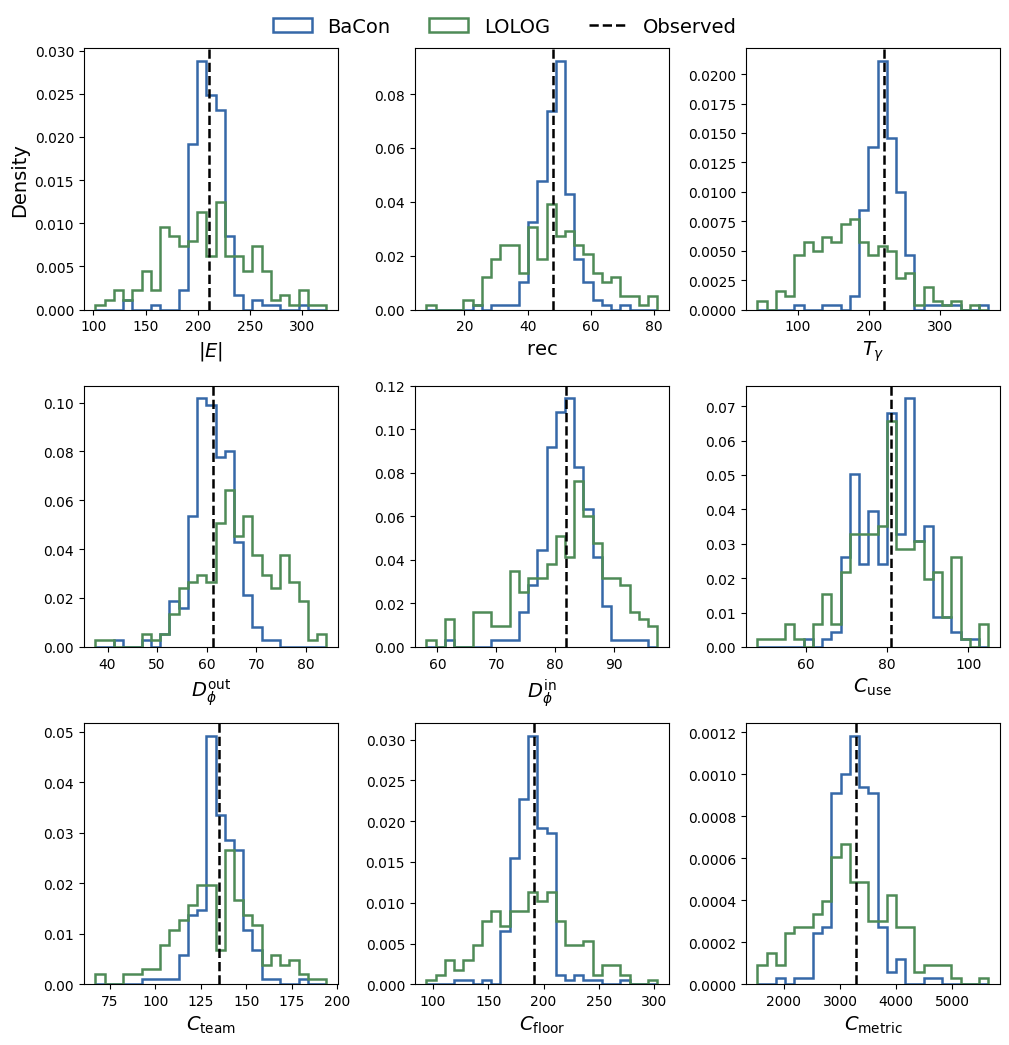

In [372]:
_stat_idx = selected_stat_indices(STATISTICS_TO_PLOT, SPEC)

fig_stats = plot_stat_distributions(_stat_idx, OUR_NAME)
if STATISTICS_TO_PLOT is None:
    fig_stats.savefig(os.path.join(PLOT_DIR, f"sufficient_statistics_spec_{SPECIFICATION}_all.pdf"), bbox_inches="tight")
else:
    fig_stats.savefig(os.path.join(PLOT_DIR, f"sufficient_statistics_spec_{SPECIFICATION}.pdf"), bbox_inches="tight")
plt.show()

## 4. GOF: in-degree and out-degree


In [350]:
def plot_degree_gof(A_obs, kind, specification, maxd, our_name, model_colors):
    if A_obs is None:
        raise FileNotFoundError(
            "Observed edge list could not be found."
        )
    models = degree_models(kind, specification, maxd, our_name)
    if not models:
        raise RuntimeError(f"No saved {kind} simulations are available.")

    obs = observed_degree_hist(A_obs, kind, maxd)
    x = np.arange(maxd + 1)
    n_models = len(models)
    width = min(0.22, 0.68 / max(n_models, 1))
    offsets = (np.arange(n_models) - (n_models - 1) / 2) * (width * 1.35)

    fig, ax = plt.subplots(figsize=(8.2, 4))
    for off, (model, M) in zip(offsets, models):
        bp = ax.boxplot([M[:, j] for j in range(M.shape[1])],
                        positions=x + off, widths=width, showfliers=False,
                        patch_artist=True, manage_ticks=False)
        for box in bp["boxes"]:
            box.set(facecolor=model_colors[model], edgecolor=model_colors[model], alpha=0.22)
        for key in ("whiskers", "caps"):
            for artist in bp[key]: artist.set(color=model_colors[model], linewidth=1.0)
        for med in bp["medians"]:
            med.set(color=model_colors[model], linewidth=1.7)
        # Dummy line gives a clean legend entry for each boxplot model.
        ax.plot([], [], color=model_colors[model], linewidth=6, alpha=0.65, label=model)

    ax.plot(x, obs, "ko-", linewidth=1.6, markersize=4, label="Observed")
    tick_labels = [str(i) for i in range(maxd)] + [f"{maxd}+"]
    ax.set_xticks(x)
    ax.set_xticklabels(tick_labels)
    ax.set_xlabel("In-degree" if kind == "indeg" else "Out-degree", fontsize=12)
    ax.set_ylabel("Number of Nodes", fontsize=12)
    ax.legend(frameon=False, ncol=min(4, len(models) + 1))
    fig.tight_layout()
    return fig

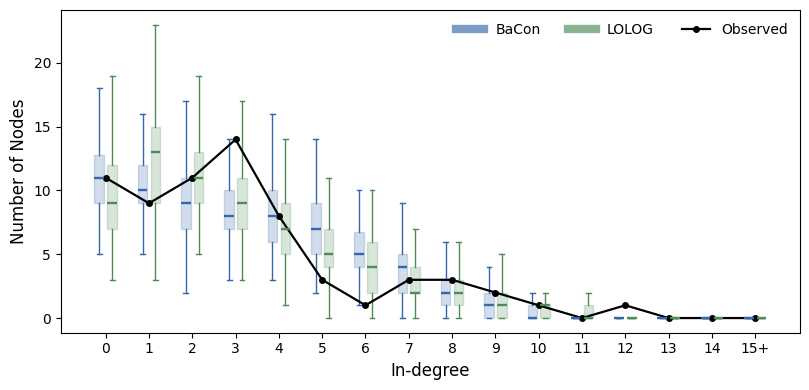

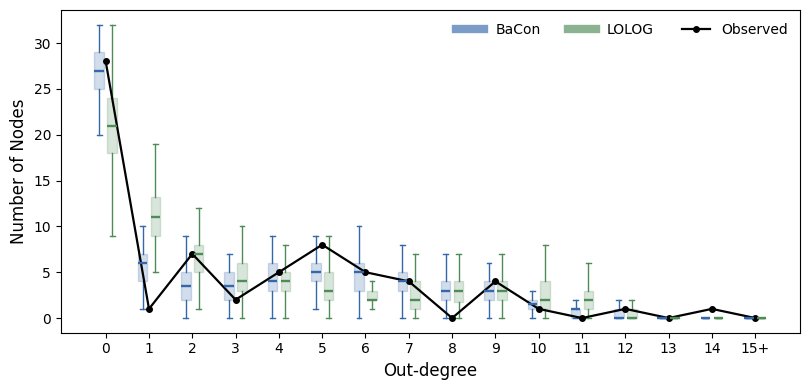

In [351]:
fig_indeg = plot_degree_gof(A_obs, "indeg", SPECIFICATION, MAX_DEGREE, OUR_NAME, MODEL_COLORS)
fig_indeg.savefig(os.path.join(PLOT_DIR, f"gof_indegree_{SPECIFICATION}.pdf"), bbox_inches="tight")
plt.show()

fig_outdeg = plot_degree_gof(A_obs, "outdeg", SPECIFICATION, MAX_DEGREE, OUR_NAME, MODEL_COLORS)
fig_outdeg.savefig(os.path.join(PLOT_DIR, f"gof_outdegree_{SPECIFICATION}.pdf"), bbox_inches="tight")
plt.show()


## 5. GOF: energy score and l1-distance

In [352]:
# ============================================================================
# ADEQUACY METRICS
# Energy Score on:
#   - in-degree distribution
#   - out-degree distribution
#   - edgewise shared-partner distribution
#
# L1 distance on:
#   - in-degree distribution
#   - out-degree distribution
#
# ============================================================================

In [353]:
obs_in = capped_hist(A_obs.sum(axis=0), MAX_DEGREE)
obs_out = capped_hist(A_obs.sum(axis=1), MAX_DEGREE)
obs_sp = shared_partner_hist(A_obs, MAX_DEGREE)

In [354]:
# ----------------------------------------------------------------------------
# Collect simulated distributions for each available model
# ----------------------------------------------------------------------------
adequacy_models = {}

# PAC-ERGM
if "gof_networks" in arrays.files:
    pac_nets = arrays["gof_networks"]

    H_in, H_out = degree_hists(pac_nets, MAX_DEGREE)
    H_sp = shared_partner_hists(pac_nets, MAX_DEGREE)

    adequacy_models[OUR_NAME] = {
        "in": H_in,
        "out": H_out,
        "sp": H_sp,
    }

# ERGM
# The R baseline already saves the histogram matrices directly.
if (
    "ergm_indeg_sim" in arrays.files
    and "ergm_outdeg_sim" in arrays.files
    and "ergm_esp_sim" in arrays.files
):
    adequacy_models["ERGM"] = {
        "in": np.asarray(arrays["ergm_indeg_sim"]),
        "out": np.asarray(arrays["ergm_outdeg_sim"]),
        "sp": np.asarray(arrays["ergm_esp_sim"]),
    }


# LOLOG
if "lolog_networks" in arrays.files:
    lolog_nets = arrays["lolog_networks"]

    H_in, H_out = degree_hists(lolog_nets, MAX_DEGREE)
    H_sp = shared_partner_hists(lolog_nets, MAX_DEGREE)

    adequacy_models["LOLOG"] = {
        "in": H_in,
        "out": H_out,
        "sp": H_sp,
    }

In [355]:
rows = []

for model, H in adequacy_models.items():
    rows.append({
        "Model": model,
        # Energy Score
        "ES in-degree": energy_score_counts(H["in"], obs_in),
        "ES out-degree": energy_score_counts(H["out"], obs_out),
        "ES shared partners": energy_score_counts(H["sp"], obs_sp),
        # L1 distance: degree distributions only, as in the thesis
        "L1 in-degree": mean_l1(H["in"], obs_in),
        "L1 out-degree": mean_l1(H["out"], obs_out),
    })

adequacy_table = (pd.DataFrame(rows).set_index("Model"))

model_order = [
    m for m in ["ERGM", "LOLOG", OUR_NAME]
    if m in adequacy_table.index
]
adequacy_table = adequacy_table.loc[model_order]

display(
    adequacy_table.rename(columns={
        "ES in-degree": "ES $d^{in}$",
        "ES out-degree": "ES $d^{out}$",
        "ES shared partners": "ES sp",
        "L1 in-degree": "L1 $d^{in}$",
        "L1 out-degree": "L1 $d^{out}$",
    }).round(1)
)

,ES $d^{in}$,ES $d^{out}$,ES sp,L1 $d^{in}$,L1 $d^{out}$
Model,,,,,
ERGM,31.6,34.2,243.8,103.1,97.3
LOLOG,5.2,10.7,23.3,29.7,43.6
BaCon,6.0,5.5,20.4,30.3,28.7


## 6: Theta and Nu Trajectories

In [356]:
# ---------------------------------------------------------------------
# Load trajectories
# ---------------------------------------------------------------------

theta_hist = np.asarray(arr("theta", arrays), dtype=float)
nu_hist = np.asarray(arr("nu", arrays), dtype=float)

# labels should already be available in the plotting notebook.
# Fall back to arrays.npz if necessary.
if "labels" not in globals():
    labels = [str(x) for x in arr("labels", arrays)]

n_iter = theta_hist.shape[0] - 1          # row 0 is the initial value
iterations = np.arange(theta_hist.shape[0])

In [357]:
# ---------------------------------------------------------------------
# Polyak--Ruppert window
# ---------------------------------------------------------------------
summary_file = os.path.join(PAC_RUN, "results_summary.json")

with open(summary_file, "r") as f:
    run_summary = json.load(f)
W = int(run_summary.get("polyak_window", 30))
W = min(W, len(theta_hist))
window_start = len(theta_hist) - W
theta_final = theta_hist[-W:].mean(axis=0)
nu_final_plot = float(run_summary["nu_final"])

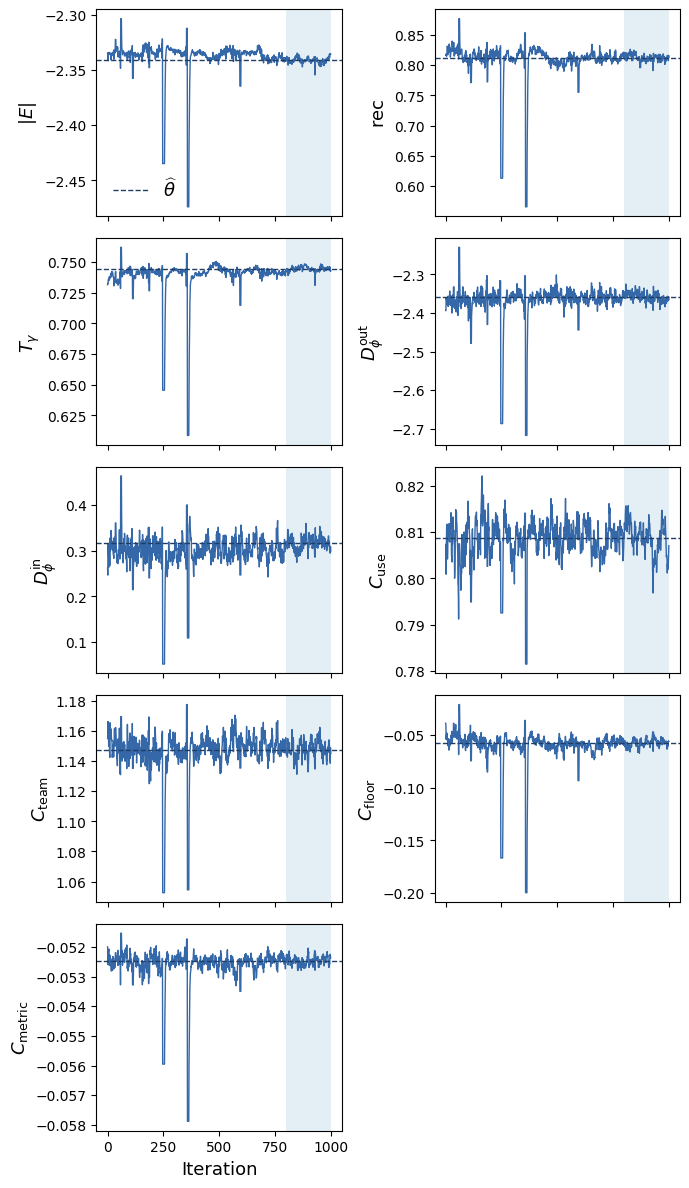

In [358]:
# ============================================================================
# 1. THETA TRAJECTORIES
# ============================================================================

p = theta_hist.shape[1]
ncols = 2
nrows = int(np.ceil(p / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(3.5 * ncols, 2.4 * nrows),
    sharex=True
)

axes = np.atleast_1d(axes).ravel()

for j, ax in enumerate(axes):

    if j >= p:
        ax.axis("off")
        continue

    ax.plot(
        iterations,
        theta_hist[:, j],
        linewidth=1.0,
        color=MODEL_COLORS[OUR_NAME],
    )

    # Final Polyak--Ruppert estimate
    ax.axhline(
        theta_final[j],
        linestyle="--",
        linewidth=1.0,
        color=darken(MODEL_COLORS[OUR_NAME], factor=0.6),
        label=r"$\widehat{\theta}$"
    )

    # Final averaging window
    ax.axvspan(
        window_start,
        iterations[-1],
        alpha=0.12
    )

    lab = labels[j]
    ax.set_ylabel(PRETTY.get(lab, lab) if "PRETTY" in globals() else lab, fontsize=13)

# x labels only on bottom row
for ax in axes[-ncols:]:
    if ax.axison:
        ax.set_xlabel("Iteration", fontsize=13)

# One legend is enough
axes[0].legend(frameon=False, fontsize=13)

fig.tight_layout()

fig.savefig(os.path.join(PLOT_DIR, f"spec{SPECIFICATION}_theta_convergence.pdf"), bbox_inches="tight")
plt.show()

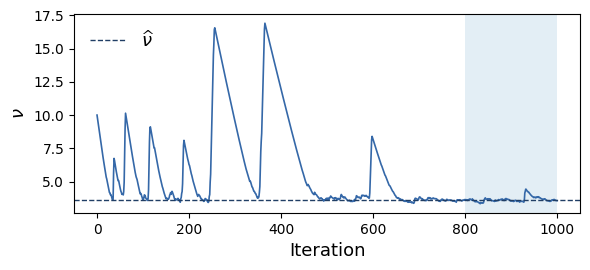

In [359]:
# ============================================================================
# 2. NU TRAJECTORY
# ============================================================================

fig, ax = plt.subplots(figsize=(6.0, 2.8))

ax.plot(
    iterations,
    nu_hist,
    color=MODEL_COLORS[OUR_NAME],
    linewidth=1.2
)

ax.axhline(
    nu_final_plot,
    linestyle="--",
    linewidth=1.0,
    color=darken(MODEL_COLORS[OUR_NAME], factor=0.6),
    label=r"$\widehat{\nu}$"
)

ax.axvspan(
    window_start,
    iterations[-1],
    alpha=0.12,
    # label="final averaging window"
)

ax.set_xlabel("Iteration", fontsize=13)
ax.set_ylabel(r"$\nu$", fontsize=13)
ax.legend(frameon=False, fontsize=13)

fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, f"spec{SPECIFICATION}_nu_convergence.pdf"), bbox_inches="tight")
plt.show()

## 7: Scalability

In [360]:
# ----------------------------------------------------------------------------
# 1. Load all scalability runs
# ----------------------------------------------------------------------------
run_files = glob(os.path.join(SCALABILITY_DIR, "run_*_r*.json"))
run_files = sorted(run_files)

scalability_runs = []
for run_file in run_files:

    with open(run_file, "r", encoding="utf-8") as f:
        r = json.load(f)

    r["_run_file"] = run_file
    scalability_runs.append(r)

# Sort by actual number of edges
scalability_runs = sorted(
    scalability_runs,
    key=lambda r: (r["m"], r.get("replicate", 0))
)

In [361]:
rows = []

for r in scalability_runs:

    T = r["times_s"]
    us = r["us_per_step"]

    rows.append({
        "target_edges": int(r["target_edges"]),
        "replicate": int(r.get("replicate", 0)),

        "m": int(r["m"]),
        "n": int(r["n"]),
        "setup_s": (
            float(T["calibration"])
            + float(T["start"])
        ),

        "fit_s": float(T["fit"]),
        "fit_per_iteration_s": float(T["fit_per_iteration"]),
        "per_network_s": float(T["per_network"]),

        "ergm_us_per_step": float(us["ergm_chain_nu0"]),
        "pac_us_per_step": float(us["pac_chain"]),

        "nu": float(r["nu_hat"]),
        "coverage": float(r["coverage_last_window"]),
        "epsilon": float(r["epsilon"]),
    })

scalability_df = pd.DataFrame(rows).sort_values(
    ["m", "replicate"]
).reset_index(drop=True)

In [362]:
def format_time(seconds):
    """Readable representation of total fitting time."""
    seconds = float(seconds)

    if seconds < 120:
        return f"{seconds:.0f} s"

    if seconds < 3600:
        return f"{seconds / 60:.1f} min"

    return f"{seconds / 3600:.1f} h"


scalability_table = scalability_df[
    [
        "m",
        "n",
        "setup_s",
        "fit_s",
        "fit_per_iteration_s",
        "per_network_s",
        "ergm_us_per_step",
        "pac_us_per_step",
    ]
].copy()


# For display only
scalability_table_display = scalability_table.copy()

scalability_table_display["fit_s"] = (
    scalability_table_display["fit_s"].map(format_time)
)

scalability_table_display = scalability_table_display.rename(
    columns={
        "m": "Edges $m$",
        "n": "Nodes $n$",
        "setup_s": "Setup (s)",
        "fit_s": "Fitting",
        "fit_per_iteration_s": "Per iteration (s)",
        "per_network_s": "Per network (s)",
        "ergm_us_per_step": r"ERGM ($\mu$s/step)",
        "pac_us_per_step": f"{OUR_NAME}" + r"($\mu$s/step)",
    }
)

display(
    scalability_table_display.style.format({
        "Edges $m$": "{:,.0f}",
        "Nodes $n$": "{:,.0f}",
        "Max. degree": "{:,.0f}",
        "Setup (s)": "{:.2f}",
        "Per iteration (s)": "{:.2f}",
        "Per network (s)": "{:.2f}",
        r"ERGM ($\mu$s/step)": "{:.0f}",
        f"{OUR_NAME}" + r"($\mu$s/step)": "{:.0f}",
    })
)

,Edges $m$,Nodes $n$,Setup (s),Fitting,Per iteration (s),Per network (s),ERGM ($\mu$s/step),BaCon($\mu$s/step)
0,105,26,0.57,75 s,0.25,0.01,94,94
1,"1,000",135,0.90,11.5 min,2.30,0.11,108,108
2,"10,014",895,20.93,1.9 h,22.58,1.03,104,104
3,"100,097","4,511",85.04,30.8 h,369.12,16.43,179,179


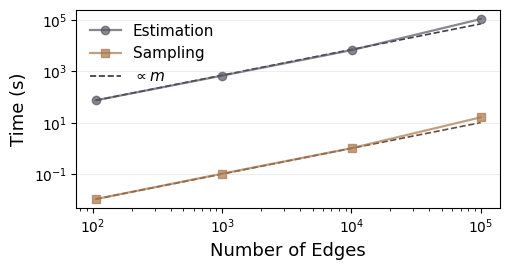

In [363]:
m = scalability_df["m"].to_numpy(dtype=float)
fit = scalability_df["fit_s"].to_numpy(dtype=float)
per_network = scalability_df["per_network_s"].to_numpy(dtype=float)


fig, ax = plt.subplots(figsize=(5.2, 2.8))


# Fitting time
ax.plot(
    m,
    fit,
    marker="o",
    linewidth=1.6,
    color='#585563',
    alpha=0.7,
    zorder=1,
    label="Estimation",
)

# Time per simulated network
ax.plot(
    m,
    per_network,
    marker="s",
    linewidth=1.6,
    color="#A9774C",
    alpha=0.7,
    zorder=1,
    label="Sampling",
)


# Linear reference lines, anchored at the first observation
ax.plot(
    m,
    fit[0] * m / m[0],
    linestyle="--",
    linewidth=1.2,
    color=darken('#585563', factor=0.5),
    zorder=-1,
    alpha=0.9,
)

ax.plot(
    m,
    per_network[0] * m / m[0],
    linestyle="--",
    linewidth=1.2,
    color=darken("#A9774C", factor=0.5),
    zorder=-1,
    alpha=0.9,
)

# Dummy entry to explain the dashed lines
ax.plot(
    [],
    [],
    linestyle="--",
    linewidth=1.2,
    color='black',
    alpha=0.8,
    label=r"$\propto m$",
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Number of Edges", fontsize=13)
ax.set_ylabel("Time (s)", fontsize=13)

ax.legend(frameon=False, loc="upper left", fontsize=11)

ax.grid(axis='y',
    which="major",
    linewidth=0.4,
    alpha=0.4,
)

fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "scalability.pdf"), bbox_inches="tight")
plt.show()

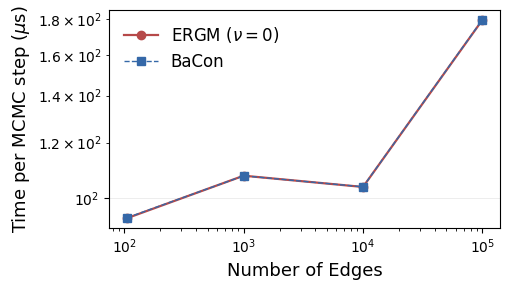

In [364]:
ergm_step = scalability_df["ergm_us_per_step"].to_numpy(dtype=float)
pac_step = scalability_df["pac_us_per_step"].to_numpy(dtype=float)


fig, ax = plt.subplots(figsize=(5.2, 3))

ax.plot(
    m,
    ergm_step,
    marker="o",
    linewidth=1.6,
    color=MODEL_COLORS["ERGM"],
    label=r"ERGM ($\nu=0$)",
)

ax.plot(
    m,
    pac_step,
    marker="s",
    linewidth=1,
    linestyle="--",
    color=MODEL_COLORS[OUR_NAME],
    label=OUR_NAME,
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(r"Number of Edges", fontsize=13)
ax.set_ylabel(r"Time per MCMC step ($\mu$s)", fontsize=13)

ax.legend(frameon=False, fontsize=12)

ax.grid(
    axis="y",
    which="major",
    linewidth=0.4,
    alpha=0.4,
)

fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "scalability_mcmc_step.pdf"), bbox_inches="tight")
plt.show()

## 8: Sensitivity analysis to band radius

In [333]:
sens = pd.read_csv(os.path.join(SENSITIVITY_DIR, "summary.csv"))
sens = sens.sort_values("m").reset_index(drop=True)

ks = sens["m"].to_numpy(float)
x = np.arange(len(ks))
xt = [f"{k:g}" for k in ks]

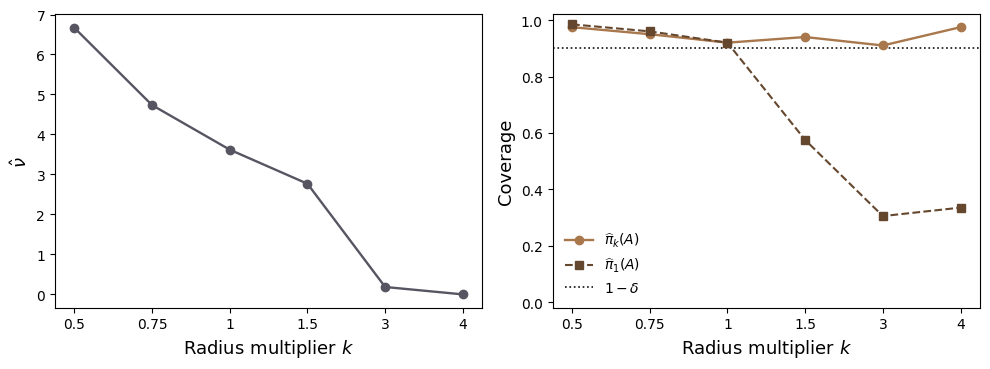

In [334]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))

# --- nu_hat
ax[0].plot(x, sens["nu_hat"], "o-", color='#585563', lw=1.7)

ax[0].set_ylabel(r"$\hat{\nu}$", fontsize=13)
ax[0].set_xlabel(r"Radius multiplier $k$", fontsize=13)
ax[0].set_xticks(x)
ax[0].set_xticklabels(xt)

# --- coverage
ax[1].plot(x, sens["pi_own"], "o-", color="#A9774C", lw=1.7, label=r"$\widehat{\pi}_{k}(A)$")
ax[1].plot(x, sens["pi_base"], "s--", color=darken("#A9774C", factor=.6), lw=1.5, label=r"$\widehat{\pi}_{1}(A)$")

ax[1].axhline(0.9, ls=":", lw=1.2, label=r"$1-\delta$", zorder=-1, color=darken("#A9774C", factor=.1))

ax[1].set_ylim(-0.02, 1.02)
ax[1].set_ylabel("Coverage", fontsize=13)
ax[1].set_xlabel(r"Radius multiplier $k$", fontsize=13)
ax[1].set_xticks(x)
ax[1].set_xticklabels(xt)
ax[1].legend(frameon=False)

plt.tight_layout()

fig.savefig(os.path.join(PLOT_DIR, f"sensitivity_nu_coverage_spec_3.pdf"), bbox_inches="tight")
plt.show()

In [335]:
tab = pd.read_csv(os.path.join(SENSITIVITY_DIR, "summary.csv"))
theta_tab = pd.read_csv(os.path.join(SENSITIVITY_DIR, "theta_by_radius.csv"), index_col=0)

print(tab.round(3).to_string())
print("\ntheta by radius:\n", theta_tab.round(3).to_string())

      m     eps  step_size  nu_hat  coverage_estimation  pi_own  pi_base      R     ES  ES_indeg  ES_outdeg  ES_esp  edges_median  edges_q05  edges_q95  frac_edges_over_2x
0  0.50   2.155        NaN   6.667                0.899   0.975    0.985  0.142  0.562     6.231      5.672  20.645         211.0     203.00     219.05                 0.0
1  0.75   3.232        NaN   4.734                0.900   0.950    0.960  0.121  0.776     5.940      5.652  20.941         212.0     198.00     224.00                 0.0
2  1.00   4.310      0.300   3.619                0.905   0.920    0.920  0.200  1.026     6.004      5.491  20.423         209.0     192.00     232.05                 0.0
3  1.50   6.465      0.133   2.767                0.870   0.940    0.575  0.528  1.310     5.940      5.734  20.104         213.5     184.95     243.15                 0.0
4  3.00  12.930      0.033   0.185                0.908   0.910    0.305  0.358  2.019     6.294      5.377  20.150         209.0     156.95

## 9: Robustness

In [11]:
# ----------------------------------------------------------------------------
# 1. Load all robustness runs
# ----------------------------------------------------------------------------
runs = []

for p in glob(os.path.join(ROBUST_DIR, "spec*_seed*.json")):
    with open(p, encoding="utf-8") as f:
        r = json.load(f)

    row = {
        "spec": int(r["specification"]),
        "seed": int(r["seed"]),
        "nu_hat": float(r["nu_hat"]),
        "coverage_window": float(r["coverage_window"]),
    }
    if "gof" in r:
        row.update({
            "coverage_postfit": float(r["gof"]["coverage"]),
            "R": float(r["gof"]["R"]),
            "ES": float(r["gof"]["ES"]),
        })
    for label, value in zip(r["labels"], r["theta_hat"]):
        row[f"theta[{label}]"] = float(value)

    runs.append(row)

robust = pd.DataFrame(runs)

In [14]:
robust

,spec,seed,nu_hat,coverage_window,coverage_postfit,R,ES,theta[edges],theta[mutual],theta[gwesp],theta[edgecov.use],theta[edgecov.team],theta[edgecov.floor],theta[edgecov.metric],theta[nodematch.GroupC],theta[nodefactor.GroupC.1],theta[nodefactor.GroupC.2],theta[gwodeg],theta[gwideg]
0,2,2,3.704740,0.900922,0.9300,0.241019,0.837253,-3.356427,0.550079,1.189743,0.829232,0.893947,0.025370,-0.042810,NaN,NaN,NaN,NaN,NaN
1,1,1,2.611876,0.890467,0.8752,0.979028,0.742548,-6.005479,NaN,2.242653,NaN,NaN,NaN,NaN,1.553427,0.001663,0.108119,NaN,NaN
2,2,3,3.787406,0.902691,0.9300,0.406996,0.857187,-3.356071,0.546959,1.189188,0.826783,0.892216,0.022576,-0.042855,NaN,NaN,NaN,NaN,NaN
3,3,1,3.576424,0.891050,0.9250,0.383047,1.007816,-2.320546,0.813289,0.738173,0.807159,1.148527,-0.065947,-0.052704,NaN,NaN,NaN,-2.369403,0.294780
4,2,4,3.854419,0.904866,0.9450,0.308408,0.861821,-3.360956,0.549700,1.188870,0.827069,0.894081,0.028673,-0.042793,NaN,NaN,NaN,NaN,NaN
5,2,5,3.736710,0.901659,0.9450,0.112155,0.810141,-3.355870,0.549829,1.189194,0.825897,0.893827,0.026691,-0.042875,NaN,NaN,NaN,NaN,NaN
6,1,5,3.428437,0.891667,0.9516,0.422662,0.618355,-6.004366,NaN,2.241444,NaN,NaN,NaN,NaN,1.549774,0.003430,0.110404,NaN,NaN
7,3,3,3.594916,0.901119,0.9600,0.307839,0.980313,-2.318620,0.810576,0.739192,0.808513,1.146442,-0.063047,-0.052736,NaN,NaN,NaN,-2.371906,0.294807
8,3,2,3.750158,0.881059,0.9500,0.231147,1.008328,-2.318811,0.812869,0.739237,0.807665,1.149655,-0.060740,-0.052652,NaN,NaN,NaN,-2.370570,0.296858
9,1,4,2.709436,0.920367,0.8094,1.388327,0.877696,-6.003641,NaN,2.240901,NaN,NaN,NaN,NaN,1.557110,0.002534,0.109448,NaN,NaN


In [17]:
coef_rows = []

for spec, d in robust.groupby("spec"):
    theta_cols = [c for c in d.columns if c.startswith("theta[")]

    for col in theta_cols:
        label = col[len("theta["):-1]

        coef_rows.append({
            "Spec": spec,
            "Statistic": PRETTY.get(label, label),
            "Mean": d[col].mean(),
            "SD": d[col].std(ddof=1),
        })

coef_summary = pd.DataFrame(coef_rows)

In [13]:
fit_metrics = [
    "nu_hat",
    "coverage_window",
    "coverage_postfit",
    "R",
    "ES",
]

fit_summary = (
    robust
    .groupby("spec")[fit_metrics]
    .agg(["mean", "std"])
)

fit_summary

nu_hat           coverage_window           coverage_postfit            \
          mean       std            mean       std             mean       std   
spec                                                                            
1     2.692372  0.445957        0.899773  0.012244            0.835  0.097621   
2     3.853374  0.193068        0.901796  0.002220            0.943  0.014405   
3     3.623757  0.071330        0.894810  0.008771            0.949  0.017464   

             R                  ES            
          mean       std      mean       std  
spec                                          
1     1.205407  0.714880  0.852462  0.246390  
2     0.305082  0.136702  0.840426  0.020543  
3     0.287392  0.062747  0.995220  0.019271